# Trabajo Práctico 03 — Árboles de decisión

**Bases de Datos Masivas (11088)** — Departamento de Ciencias Básicas
**2° Cuatrimestre 2026** — Universidad Nacional de Luján

---

**Alumno/a:** Federico Kasparian

---

## Índice

1. [Entropía, ganancia de información e ID3 (`parcial.csv`)](#ej1)
2. [Gliomas (`gliomas.csv`)](#ej2)
3. [Informalidad laboral — EPH (`asalariados_eph.csv`)](#ej3)


In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from collections import Counter

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate, GridSearchCV
from sklearn.tree import DecisionTreeClassifier, plot_tree, export_text
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, balanced_accuracy_score, confusion_matrix,
                             classification_report, ConfusionMatrixDisplay)

pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 30)
SEED = 42

<a id="ej1"></a>
## 1. Entropía, ganancia de información y construcción del árbol (ID3)

Se implementan a mano:

- `entropia(y)`: $H(Y) = -\sum_i p_i \log_2 p_i$
- `ganancia_informacion(df, A, clase)`: $G(A) = H(Y) - \sum_{v \in A} \frac{|S_v|}{|S|} H(Y \mid A=v)$

y con ellas el algoritmo **ID3** (Quinlan, 1986): en cada nodo se elige el atributo de mayor ganancia,
se abre una rama por cada valor y se repite recursivamente hasta que el nodo sea puro o no queden atributos.

In [2]:
parcial = pd.read_csv("data/parcial.csv")
parcial

,ASISTENCIA,TPS,TRABAJA,MODALIDAD,APRUEBA
0,alta,completos,no,presencial,si
1,alta,parciales,si,virtual,si
2,alta,completos,si,presencial,si
3,alta,parciales,no,virtual,si
4,baja,completos,no,presencial,no
5,baja,parciales,si,presencial,no
6,baja,completos,si,virtual,no
7,baja,parciales,no,virtual,no
8,media,completos,si,presencial,si
9,media,completos,no,virtual,si


In [3]:
def entropia(y):
    # Entropía de Shannon (en bits) de una secuencia de etiquetas.
    n = len(y)
    if n == 0:
        return 0.0
    p = np.array(list(Counter(y).values())) / n
    return float(-(p * np.log2(p)).sum())


def entropia_condicional(df, atributo, clase):
    # Promedio ponderado de la entropía de la clase en cada partición inducida por el atributo.
    n = len(df)
    return sum(len(sub) / n * entropia(sub[clase]) for _, sub in df.groupby(atributo))


def ganancia_informacion(df, atributo, clase):
    # G(A) = H(clase) - H(clase | A)
    return entropia(df[clase]) - entropia_condicional(df, atributo, clase)


CLASE = "APRUEBA"
ATRIBUTOS = [c for c in parcial.columns if c != CLASE]
print(f"Distribución de la clase: {dict(Counter(parcial[CLASE]))}")
print(f"H(APRUEBA) = {entropia(parcial[CLASE]):.4f} bits")

Distribución de la clase: {'si': 8, 'no': 6}
H(APRUEBA) = 0.9852 bits


### 1.1 Paso 1 — Nodo raíz

Para cada atributo se calcula la entropía de cada partición, la entropía condicional y la ganancia.

In [4]:
def detalle_atributo(df, atributo, clase):
    filas = []
    for v, sub in df.groupby(atributo):
        c = Counter(sub[clase])
        filas.append({"atributo": atributo, "valor": v, "n": len(sub),
                      "si": c.get("si", 0), "no": c.get("no", 0),
                      "H(valor)": round(entropia(sub[clase]), 4)})
    return pd.DataFrame(filas)

display(pd.concat([detalle_atributo(parcial, a, CLASE) for a in ATRIBUTOS], ignore_index=True))

ganancias_raiz = pd.DataFrame({
    "H(clase|A)": {a: entropia_condicional(parcial, a, CLASE) for a in ATRIBUTOS},
    "Ganancia":   {a: ganancia_informacion(parcial, a, CLASE) for a in ATRIBUTOS},
}).sort_values("Ganancia", ascending=False).round(4)
ganancias_raiz

,atributo,valor,n,si,no,H(valor)
0,ASISTENCIA,alta,4,4,0,-0.0000
1,ASISTENCIA,baja,4,0,4,-0.0000
2,ASISTENCIA,media,6,4,2,0.9183
3,TPS,completos,7,5,2,0.8631
4,TPS,parciales,7,3,4,0.9852
5,TRABAJA,no,6,4,2,0.9183
6,TRABAJA,si,8,4,4,1.0000
7,MODALIDAD,presencial,7,4,3,0.9852
8,MODALIDAD,virtual,7,4,3,0.9852


,H(clase|A),Ganancia
ASISTENCIA,0.3936,0.5917
TPS,0.9242,0.0611
TRABAJA,0.9650,0.0202
MODALIDAD,0.9852,0.0000


### 1.2 Construcción recursiva (ID3)

La función registra, en cada nodo, la ganancia de todos los atributos candidatos para dejar trazado
el razonamiento paso a paso.

In [5]:
def id3(df, clase, atributos, camino="RAÍZ", traza=None):
    y = df[clase]
    cuenta = dict(Counter(y))
    if y.nunique() == 1:                      # nodo puro -> hoja
        traza.append(f"[{camino}] n={len(df)} {cuenta} -> HOJA '{y.iloc[0]}' (nodo puro)")
        return y.iloc[0]
    if not atributos:                         # sin atributos -> clase mayoritaria
        traza.append(f"[{camino}] n={len(df)} {cuenta} -> HOJA '{y.mode()[0]}' (sin atributos)")
        return y.mode()[0]

    gan = {a: ganancia_informacion(df, a, clase) for a in atributos}
    mejor = max(gan, key=gan.get)
    detalle = ", ".join(f"{a}={g:.4f}" for a, g in sorted(gan.items(), key=lambda t: -t[1]))
    traza.append(f"[{camino}] n={len(df)} {cuenta} H={entropia(y):.4f} | ganancias: {detalle} -> divide por {mejor}")

    resto = [a for a in atributos if a != mejor]
    return {mejor: {v: id3(sub, clase, resto, f"{camino} > {mejor}={v}", traza)
                    for v, sub in df.groupby(mejor)}}


def imprimir_arbol(arbol, sangria=""):
    if not isinstance(arbol, dict):
        print(f"{sangria}=> {arbol}")
        return
    (atr, ramas), = arbol.items()
    for v, sub in ramas.items():
        if isinstance(sub, dict):
            print(f"{sangria}{atr} = {v}")
            imprimir_arbol(sub, sangria + "    ")
        else:
            print(f"{sangria}{atr} = {v}  =>  APRUEBA = {sub}")


traza = []
arbol_id3 = id3(parcial, CLASE, ATRIBUTOS, traza=traza)
print("\n".join(traza))
print("\nÁRBOL RESULTANTE\n" + "-" * 40)
imprimir_arbol(arbol_id3)

[RAÍZ] n=14 {'si': 8, 'no': 6} H=0.9852 | ganancias: ASISTENCIA=0.5917, TPS=0.0611, TRABAJA=0.0202, MODALIDAD=0.0000 -> divide por ASISTENCIA
[RAÍZ > ASISTENCIA=alta] n=4 {'si': 4} -> HOJA 'si' (nodo puro)
[RAÍZ > ASISTENCIA=baja] n=4 {'no': 4} -> HOJA 'no' (nodo puro)
[RAÍZ > ASISTENCIA=media] n=6 {'si': 4, 'no': 2} H=0.9183 | ganancias: TPS=0.4591, TRABAJA=0.2516, MODALIDAD=0.0000 -> divide por TPS
[RAÍZ > ASISTENCIA=media > TPS=completos] n=3 {'si': 3} -> HOJA 'si' (nodo puro)
[RAÍZ > ASISTENCIA=media > TPS=parciales] n=3 {'si': 1, 'no': 2} H=0.9183 | ganancias: TRABAJA=0.9183, MODALIDAD=0.2516 -> divide por TRABAJA
[RAÍZ > ASISTENCIA=media > TPS=parciales > TRABAJA=no] n=1 {'si': 1} -> HOJA 'si' (nodo puro)
[RAÍZ > ASISTENCIA=media > TPS=parciales > TRABAJA=si] n=2 {'no': 2} -> HOJA 'no' (nodo puro)

ÁRBOL RESULTANTE
----------------------------------------
ASISTENCIA = alta  =>  APRUEBA = si
ASISTENCIA = baja  =>  APRUEBA = no
ASISTENCIA = media
    TPS = completos  =>  APRUEBA = 

In [6]:
def predecir(arbol, fila):
    while isinstance(arbol, dict):
        (atr, ramas), = arbol.items()
        arbol = ramas[fila[atr]]
    return arbol

pred = parcial.apply(lambda f: predecir(arbol_id3, f), axis=1)
print(f"Exactitud sobre el propio dataset: {(pred == parcial[CLASE]).mean():.0%}")

Exactitud sobre el propio dataset: 100%


### 1.3 Comparación con Scikit-Learn

Scikit-Learn implementa **CART**: árboles **binarios** y atributos numéricos, por lo que se codifican
los atributos con *one-hot*. Con `criterion="entropy"` usa la misma medida de impureza; la estructura
puede diferir porque cada corte es binario (p. ej. `ASISTENCIA=baja` vs. resto).

In [7]:
Xp = pd.get_dummies(parcial[ATRIBUTOS], dtype=int)
sk_parcial = DecisionTreeClassifier(criterion="entropy", random_state=SEED).fit(Xp, parcial[CLASE])
print(export_text(sk_parcial, feature_names=list(Xp.columns)))

|--- ASISTENCIA_baja <= 0.50
|   |--- TPS_parciales <= 0.50
|   |   |--- class: si
|   |--- TPS_parciales >  0.50
|   |   |--- TRABAJA_si <= 0.50
|   |   |   |--- class: si
|   |   |--- TRABAJA_si >  0.50
|   |   |   |--- ASISTENCIA_alta <= 0.50
|   |   |   |   |--- class: no
|   |   |   |--- ASISTENCIA_alta >  0.50
|   |   |   |   |--- class: si
|--- ASISTENCIA_baja >  0.50
|   |--- class: no



**Conclusión del punto 1.**

| Nodo | Candidatos (ganancia) | Elegido |
|---|---|---|
| Raíz (8 si / 6 no, H = 0,9852) | ASISTENCIA 0,5917 · TPS 0,0611 · TRABAJA 0,0202 · MODALIDAD 0,0000 | **ASISTENCIA** |
| ASISTENCIA = media (4 si / 2 no, H = 0,9183) | TPS 0,4591 · TRABAJA 0,2516 · MODALIDAD 0,0000 | **TPS** |
| … TPS = parciales (1 si / 2 no, H = 0,9183) | TRABAJA 0,9183 · MODALIDAD 0,2516 | **TRABAJA** |

```
ASISTENCIA
├── alta  → APRUEBA = si
├── baja  → APRUEBA = no
└── media → TPS
            ├── completos → si
            └── parciales → TRABAJA
                            ├── no → si
                            └── si → no
```

Las ramas *alta* y *baja* quedan puras en el primer corte. `MODALIDAD` tiene ganancia nula en todos los
nodos y nunca se usa. El árbol clasifica bien las 14 filas (100 %, esperable en ID3 sin poda y sin registros
contradictorios). Scikit-Learn (CART binario) llega a reglas equivalentes, pero su último corte usa
`ASISTENCIA_alta` en vez de cerrar en `TRABAJA`, porque al ser binario `ASISTENCIA` puede volver a aparecer.

<a id="ej2"></a>
## 2. Gliomas (`gliomas.csv`)

### 2.a Tema del dataset

El dataset proviene de *Glioma Grading Clinical and Mutation Features* (UCI, Tasci et al., 2022),
construido con pacientes del proyecto **The Cancer Genome Atlas (TCGA)**. Los gliomas son los tumores
primarios más frecuentes del sistema nervioso central y se clasifican en:

- **LGG** (*Lower-Grade Glioma*, grados II–III), de evolución más lenta, y
- **GBM** (*Glioblastoma Multiforme*, grado IV), el más agresivo.

El grado se determina normalmente con histopatología; la pregunta del dataset es si se puede **predecir
el grado a partir de datos clínicos (sexo, edad al diagnóstico, raza) y del estado de mutación de los 20
genes más frecuentemente mutados** (IDH1, TP53, ATRX, …), reduciendo costos de secuenciación al
identificar el subconjunto de genes más informativo. Es una tarea de **clasificación binaria**.

In [8]:
g = pd.read_csv("data/gliomas.csv")
print(g.shape)
print("Faltantes:", g.isna().sum().sum())
display(g.head())
display(g["grado"].value_counts().to_frame("n").assign(pct=lambda d: (d.n / d.n.sum() * 100).round(1)))
display(g.groupby("grado")[["edad_diagnostico", "IDH1", "ATRX", "TP53", "CIC", "PTEN", "EGFR"]].mean().round(2))

(839, 24)
Faltantes: 0


,sexo,edad_diagnostico,raza,IDH1,TP53,ATRX,PTEN,EGFR,CIC,MUC16,PIK3CA,NF1,PIK3R1,FUBP1,RB1,NOTCH1,BCOR,CSMD3,SMARCA4,GRIN2A,IDH2,FAT4,PDGFRA,grado
0,Masculino,51.30,Blanca,1,0,0,0,0,0,0,1,0,0,1,0,0,0,0,0,0,0,0,0,LGG
1,Masculino,38.72,Blanca,1,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,LGG
2,Masculino,35.17,Blanca,1,1,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,LGG
3,Femenino,32.78,Blanca,1,1,1,0,0,0,1,0,0,1,0,0,0,0,0,0,0,0,1,0,LGG
4,Masculino,31.51,Blanca,1,1,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,LGG


,n,pct
grado,,
LGG,487,58.0
GBM,352,42.0


,edad_diagnostico,IDH1,ATRX,TP53,CIC,PTEN,EGFR
grado,,,,,,,
GBM,60.70,0.07,0.10,0.32,0.01,0.33,0.23
LGG,43.87,0.78,0.38,0.48,0.22,0.05,0.06


**Codificación.** `sexo` y `raza` son categóricas nominales → *one-hot*. Los genes ya son 0/1 y la edad es
numérica, por lo que no requieren transformación (los árboles no necesitan normalización).
Clase positiva: **GBM** (el tumor agresivo, el que más interesa detectar).

In [9]:
Xg = pd.get_dummies(g.drop(columns="grado"), columns=["sexo", "raza"], dtype=int)
yg = (g["grado"] == "GBM").astype(int)          # 1 = GBM, 0 = LGG

Xg_tr, Xg_te, yg_tr, yg_te = train_test_split(Xg, yg, test_size=0.2, stratify=yg, random_state=SEED)
print(f"Entrenamiento: {Xg_tr.shape}  |  Test: {Xg_te.shape}")
print(f"% GBM train = {yg_tr.mean():.3f}  |  % GBM test = {yg_te.mean():.3f}")

Entrenamiento: (671, 27)  |  Test: (168, 27)


% GBM train = 0.420  |  % GBM test = 0.417


In [10]:
def evaluar(modelo, Xtr, ytr, Xte, yte, nombre="modelo"):
    p_tr, p_te = modelo.predict(Xtr), modelo.predict(Xte)
    proba = modelo.predict_proba(Xte)[:, 1]
    return {
        "modelo": nombre,
        "prof.": modelo.get_depth(), "hojas": modelo.get_n_leaves(),
        "acc_train": accuracy_score(ytr, p_tr), "acc_test": accuracy_score(yte, p_te),
        "bal_acc": balanced_accuracy_score(yte, p_te),
        "precision": precision_score(yte, p_te, zero_division=0),
        "recall": recall_score(yte, p_te), "f1": f1_score(yte, p_te),
        "auc": roc_auc_score(yte, proba),
    }

### 2.b Árbol con parámetros por defecto (hold-out 80/20)

,modelo,prof.,hojas,acc_train,acc_test,bal_acc,precision,recall,f1,auc
0,"default (gini, sin límites)",23,126,1.0,0.792,0.785,0.754,0.743,0.748,0.785


              precision    recall  f1-score   support

         LGG       0.82      0.83      0.82        98
         GBM       0.75      0.74      0.75        70

    accuracy                           0.79       168
   macro avg       0.79      0.78      0.79       168
weighted avg       0.79      0.79      0.79       168


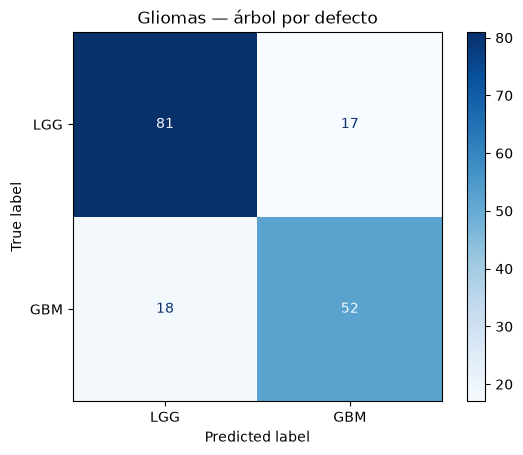

In [11]:
arbol_g = DecisionTreeClassifier(random_state=SEED).fit(Xg_tr, yg_tr)
res_g_base = evaluar(arbol_g, Xg_tr, yg_tr, Xg_te, yg_te, "default (gini, sin límites)")
display(pd.DataFrame([res_g_base]).round(3))
print(classification_report(yg_te, arbol_g.predict(Xg_te), target_names=["LGG", "GBM"]))
ConfusionMatrixDisplay.from_estimator(arbol_g, Xg_te, yg_te, display_labels=["LGG", "GBM"], cmap="Blues")
plt.title("Gliomas — árbol por defecto"); plt.show()

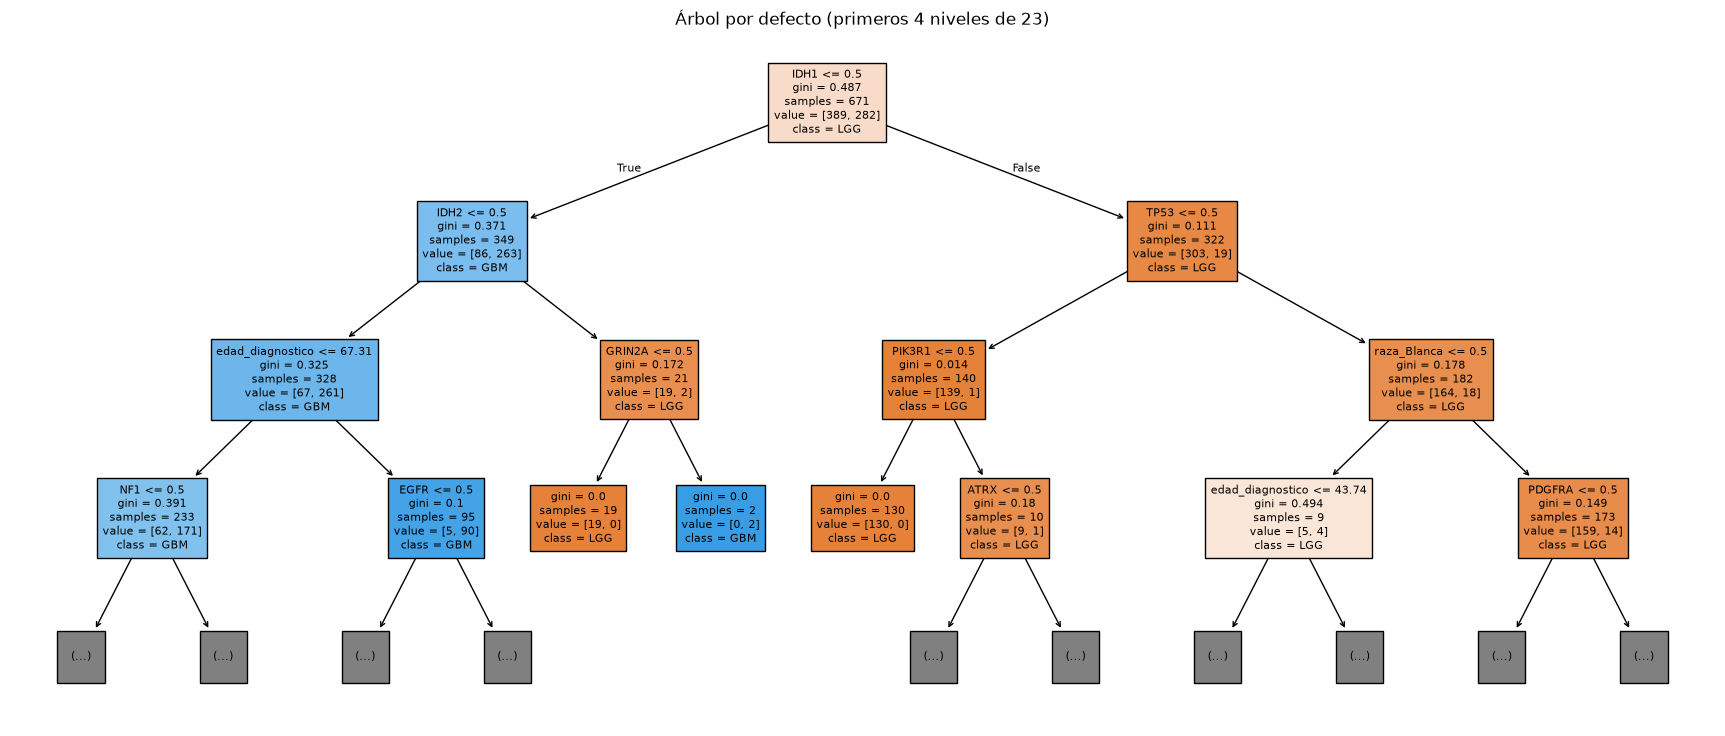

In [12]:
plt.figure(figsize=(22, 9))
plot_tree(arbol_g, feature_names=Xg.columns, class_names=["LGG", "GBM"], filled=True,
          max_depth=3, fontsize=8, impurity=True, proportion=False)
plt.title(f"Árbol por defecto (primeros 4 niveles de {arbol_g.get_depth()})"); plt.show()

El árbol sin restricciones alcanza 100 % en entrenamiento pero 79,2 % en test, con profundidad 23 y 126 hojas:
crece hasta aislar casi cada paciente, es decir, **sobreajusta**. El primer corte es `IDH1` (la mutación de
IDH1 es típica de los gliomas de bajo grado), luego `IDH2` / `TP53`, y la edad aparece en los niveles más profundos,
donde se usa sobre todo para "memorizar" pacientes.

### 2.c Exploración de configuraciones

1. Curva de complejidad (profundidad máxima) con validación cruzada sobre el conjunto de entrenamiento.
2. Búsqueda en grilla (`GridSearchCV`, 5 folds estratificados, sólo sobre *train*) de `criterion`,
   `max_depth`, `min_samples_leaf` y `class_weight`.
3. Poda por costo-complejidad (`ccp_alpha`).

El conjunto de test se usa **una sola vez** al final para no contaminar la selección del modelo.

,max_depth,acc_train_cv,acc_val_cv,std_val
0,1,0.844,0.843,0.022
1,2,0.869,0.869,0.016
2,3,0.875,0.866,0.013
3,4,0.883,0.861,0.014
4,5,0.892,0.852,0.023
5,6,0.903,0.843,0.025
6,7,0.915,0.833,0.029
7,8,0.930,0.824,0.018
8,9,0.941,0.823,0.024
9,10,0.950,0.817,0.024


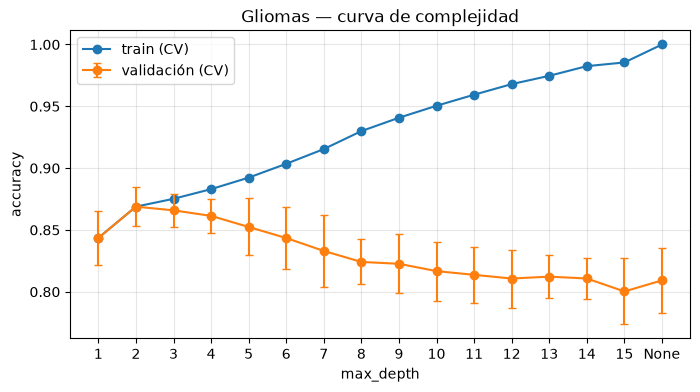

In [13]:
cv5 = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
filas = []
for d in list(range(1, 16)) + [None]:
    r = cross_validate(DecisionTreeClassifier(max_depth=d, random_state=SEED), Xg_tr, yg_tr,
                       cv=cv5, scoring="accuracy", return_train_score=True)
    filas.append({"max_depth": "None" if d is None else d,
                  "acc_train_cv": r["train_score"].mean(), "acc_val_cv": r["test_score"].mean(),
                  "std_val": r["test_score"].std()})
curva_g = pd.DataFrame(filas)
display(curva_g.round(3))

plt.figure(figsize=(8, 4))
plt.plot(curva_g["max_depth"].astype(str), curva_g["acc_train_cv"], "o-", label="train (CV)")
plt.errorbar(curva_g["max_depth"].astype(str), curva_g["acc_val_cv"], yerr=curva_g["std_val"],
             fmt="o-", capsize=3, label="validación (CV)")
plt.xlabel("max_depth"); plt.ylabel("accuracy"); plt.title("Gliomas — curva de complejidad")
plt.legend(); plt.grid(alpha=.3); plt.show()

In [14]:
grid = {
    "criterion": ["gini", "entropy"],
    "max_depth": [2, 3, 4, 5, 6, 8, None],
    "min_samples_leaf": [1, 5, 10, 20, 40],
    "class_weight": [None, "balanced"],
}
gs_g = GridSearchCV(DecisionTreeClassifier(random_state=SEED), grid, cv=cv5,
                    scoring="accuracy").fit(Xg_tr, yg_tr)
res = pd.DataFrame(gs_g.cv_results_)
cols = ["param_criterion", "param_max_depth", "param_min_samples_leaf", "param_class_weight",
        "mean_test_score", "std_test_score", "rank_test_score"]
display(res.sort_values(["rank_test_score", "param_max_depth"])[cols].head(12).round(4))
print(f"Configuraciones empatadas en el 1er puesto: {(res.rank_test_score == 1).sum()} de {len(res)}")
print("Mejor configuración (la primera del empate):", gs_g.best_params_, f"| accuracy CV = {gs_g.best_score_:.4f}")

,param_criterion,param_max_depth,param_min_samples_leaf,param_class_weight,mean_test_score,std_test_score,rank_test_score
0,gini,2,1,None,0.8688,0.0155,1
1,gini,2,5,None,0.8688,0.0155,1
2,gini,2,10,None,0.8688,0.0155,1
35,entropy,2,1,None,0.8688,0.0155,1
36,entropy,2,5,None,0.8688,0.0155,1
37,entropy,2,10,None,0.8688,0.0155,1
71,gini,2,5,balanced,0.8688,0.0155,1
72,gini,2,10,balanced,0.8688,0.0155,1
105,entropy,2,1,balanced,0.8688,0.0155,1
106,entropy,2,5,balanced,0.8688,0.0155,1


Configuraciones empatadas en el 1er puesto: 17 de 140
Mejor configuración (la primera del empate): {'class_weight': None, 'criterion': 'gini', 'max_depth': 2, 'min_samples_leaf': 1} | accuracy CV = 0.8688


Mejor ccp_alpha por CV: 0.00917


,ccp_alpha,acc_val_cv,hojas
37,0.0092,0.8688,3
35,0.0054,0.8643,6
36,0.0067,0.8629,5
34,0.0036,0.8598,6
33,0.0031,0.8554,9
38,0.0289,0.8524,2
27,0.0024,0.8465,21
28,0.0025,0.8465,21


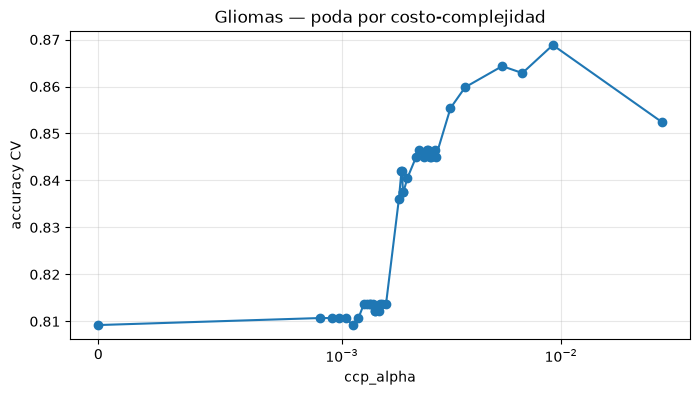

In [15]:
path = DecisionTreeClassifier(random_state=SEED).cost_complexity_pruning_path(Xg_tr, yg_tr)
alphas = np.unique(np.round(path.ccp_alphas, 5))[:-1]
filas = []
for a in alphas:
    r = cross_validate(DecisionTreeClassifier(ccp_alpha=a, random_state=SEED), Xg_tr, yg_tr, cv=cv5, scoring="accuracy")
    filas.append({"ccp_alpha": a, "acc_val_cv": r["test_score"].mean(),
                  "hojas": DecisionTreeClassifier(ccp_alpha=a, random_state=SEED).fit(Xg_tr, yg_tr).get_n_leaves()})
poda = pd.DataFrame(filas)
mejor_alpha = poda.loc[poda.acc_val_cv.idxmax(), "ccp_alpha"]
print(f"Mejor ccp_alpha por CV: {mejor_alpha}")
display(poda.sort_values("acc_val_cv", ascending=False).head(8).round(4))

fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(poda.ccp_alpha, poda.acc_val_cv, "o-"); ax.set_xscale("symlog", linthresh=1e-3)
ax.set_xlabel("ccp_alpha"); ax.set_ylabel("accuracy CV"); ax.set_title("Gliomas — poda por costo-complejidad")
ax.grid(alpha=.3); plt.show()

#### Comparación final en el conjunto de test

In [16]:
modelos_g = {
    "default (gini, sin límites)": arbol_g,
    "max_depth=3 (curva)": DecisionTreeClassifier(max_depth=3, random_state=SEED).fit(Xg_tr, yg_tr),
    f"GridSearch {gs_g.best_params_}": gs_g.best_estimator_,
    f"poda ccp_alpha={mejor_alpha}": DecisionTreeClassifier(ccp_alpha=mejor_alpha, random_state=SEED).fit(Xg_tr, yg_tr),
}
comp_g = pd.DataFrame([evaluar(m, Xg_tr, yg_tr, Xg_te, yg_te, n) for n, m in modelos_g.items()]).round(3)
comp_g

,modelo,prof.,hojas,acc_train,acc_test,bal_acc,precision,recall,f1,auc
0,"default (gini, sin límites)",23,126,1.000,0.792,0.785,0.754,0.743,0.748,0.785
1,max_depth=3 (curva),3,8,0.872,0.869,0.880,0.786,0.943,0.857,0.909
2,"GridSearch {'class_weight': None, 'criterion':...",2,4,0.869,0.869,0.880,0.786,0.943,0.857,0.888
3,poda ccp_alpha=0.00917,2,3,0.869,0.869,0.880,0.786,0.943,0.857,0.879


|--- IDH1 <= 0.50
|   |--- IDH2 <= 0.50
|   |   |--- weights: [67.00, 261.00] class: 1
|   |--- IDH2 >  0.50
|   |   |--- weights: [19.00, 2.00] class: 0
|--- IDH1 >  0.50
|   |--- TP53 <= 0.50
|   |   |--- weights: [139.00, 1.00] class: 0
|   |--- TP53 >  0.50
|   |   |--- weights: [164.00, 18.00] class: 0



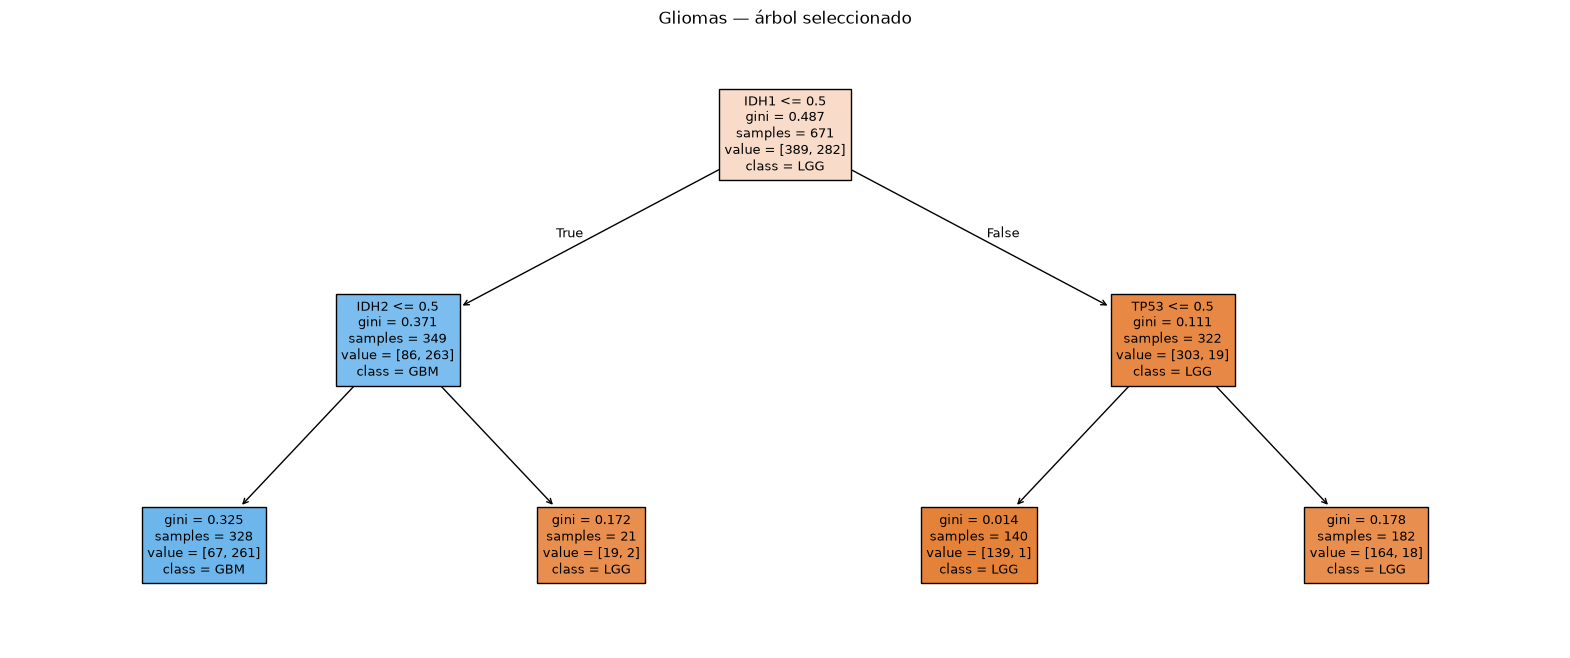

,importancia
IDH1,0.886
IDH2,0.106
TP53,0.007


In [17]:
final_g = gs_g.best_estimator_
print(export_text(final_g, feature_names=list(Xg.columns), show_weights=True))
plt.figure(figsize=(20, 8))
plot_tree(final_g, feature_names=Xg.columns, class_names=["LGG", "GBM"], filled=True, fontsize=9)
plt.title("Gliomas — árbol seleccionado"); plt.show()

imp = pd.Series(final_g.feature_importances_, index=Xg.columns).sort_values(ascending=False)
display(imp[imp > 0].round(3).to_frame("importancia"))

#### Estabilidad: ¿la mejora es real o depende de la partición?

Con 168 registros de test, un punto de accuracy equivale a menos de 2 pacientes. Se repite el hold-out 80/20
con 30 semillas distintas para comparar el árbol por defecto contra el seleccionado.

In [18]:
filas = []
for s in range(30):
    a, b, c, d = train_test_split(Xg, yg, test_size=0.2, stratify=yg, random_state=s)
    for nombre, params in [("default", {}), ("seleccionado", gs_g.best_params_)]:
        m = DecisionTreeClassifier(random_state=SEED, **params).fit(a, c)
        filas.append({"modelo": nombre, "semilla": s, "acc_test": accuracy_score(d, m.predict(b)),
                      "recall_GBM": recall_score(d, m.predict(b))})
estab = pd.DataFrame(filas)
estab.groupby("modelo")[["acc_test", "recall_GBM"]].agg(["mean", "std", "min", "max"]).round(3)

acc_test                      recall_GBM                     
                 mean    std    min    max       mean    std    min    max
modelo                                                                    
default         0.805  0.021  0.762  0.845      0.758  0.047  0.686  0.857
seleccionado    0.867  0.022  0.810  0.905      0.924  0.035  0.800  0.971

**Conclusiones del punto 2** (ver el detalle en el `.md` teórico):

- El árbol por defecto sobreajusta (100 % en train vs. 79,2 % en test; 126 hojas) y no es interpretable.
- La curva de complejidad muestra que la accuracy de validación es máxima con `max_depth` = 2–3 (≈ 0,87) y cae
  a medida que el árbol crece, mientras la de entrenamiento sube hasta 1.
- `GridSearchCV` encuentra muchas configuraciones empatadas en 0,869: 17 de las 140 empatan con exactamente el mismo puntaje fold a fold: dan **las mismas predicciones que un árbol de 2 niveles**,
  así que `criterion`, `min_samples_leaf` y `class_weight` casi no importan una vez limitada la profundidad.
  La poda por `ccp_alpha` llega a la misma conclusión (3 hojas).
- El árbol elegido (4 hojas: `IDH1`, `IDH2`, `TP53`) obtiene **86,9 % de accuracy y 94,3 % de recall de GBM** en test,
  ≈ 8 puntos más que el árbol por defecto, con muchísimas menos reglas. Regla principal: *IDH1 y IDH2 sin mutar ⇒ GBM*.
- `IDH1` concentra el 89 % de la importancia: casi toda la información está en ese gen. La edad, que en el árbol
  por defecto tenía 23 % de importancia, desaparece del modelo podado: era usada para sobreajustar.
- Repetido con 30 semillas, el árbol simple gana siempre en promedio (0,867 vs. 0,805 de accuracy; 0,92 vs. 0,76 de
  recall de GBM), así que la mejora no depende de la partición.

<a id="ej3"></a>
## 3. Informalidad laboral en asalariados — EPH 1T 2026

### 3.a Tema del dataset

Cada fila es un **asalariado** (obrero/empleado, incluido el servicio doméstico) relevado por la
**Encuesta Permanente de Hogares** del INDEC en el 1er trimestre de 2026. Se describen características
personales (región, sexo, edad, nivel educativo) y del puesto (sector, rama, calificación, tamaño del
establecimiento, lugar de trabajo, antigüedad, temporalidad, horas e ingreso).

El tema es la **informalidad laboral asalariada**: el INDEC considera informal ("no registrado") al
asalariado al que su empleador **no le realiza el descuento jubilatorio** (pregunta `PP07H`).

In [19]:
eph = pd.read_csv("data/asalariados_eph.csv")
print(eph.shape)
display(eph.head())
display(eph.isna().sum().to_frame("faltantes").assign(pct=lambda d: (d.faltantes / len(eph) * 100).round(1)))

(13938, 14)


,region,sexo,edad,nivel_educativo,sector,rama,calificacion,tamanio_establecimiento,lugar_trabajo,antiguedad,empleo_temporario,horas_semanales,ingreso_mensual,informal
0,Patagonia,Mujer,44,Superior completo,Estatal,Enseñanza,Profesional,8.0,Local/oficina/taller,Más de 5 años,no,30.0,NaN,no
1,Noroeste,Mujer,56,Superior incompleto,Estatal,Administración pública,Técnica,8.0,Local/oficina/taller,Más de 5 años,no,20.0,600000.0,no
2,Noroeste,Mujer,48,Primario completo,Privado,Servicio doméstico,No calificada,NaN,NaN,NaN,NaN,12.0,150000.0,si
3,Noroeste,Mujer,26,Secundario completo,Privado,Comercio,Operativa,3.0,Local/oficina/taller,1 a 5 años,no,40.0,1200000.0,no
4,Noroeste,Mujer,25,Secundario completo,Privado,Comercio,Operativa,3.0,Local/oficina/taller,1 a 5 años,si,40.0,600000.0,si


,faltantes,pct
region,0,0.0
sexo,0,0.0
edad,0,0.0
nivel_educativo,0,0.0
sector,0,0.0
rama,0,0.0
calificacion,16,0.1
tamanio_establecimiento,3869,27.8
lugar_trabajo,1314,9.4
antiguedad,1401,10.1


### 3.b Variable objetivo

La variable a modelar es **`informal`** (si/no). Se analiza su distribución.

,n,pct
informal,,
no,8694,62.38
si,5244,37.62


Ratio mayoritaria/minoritaria: 1.66 : 1
Accuracy de un clasificador trivial que siempre dice 'no': 62.4 %


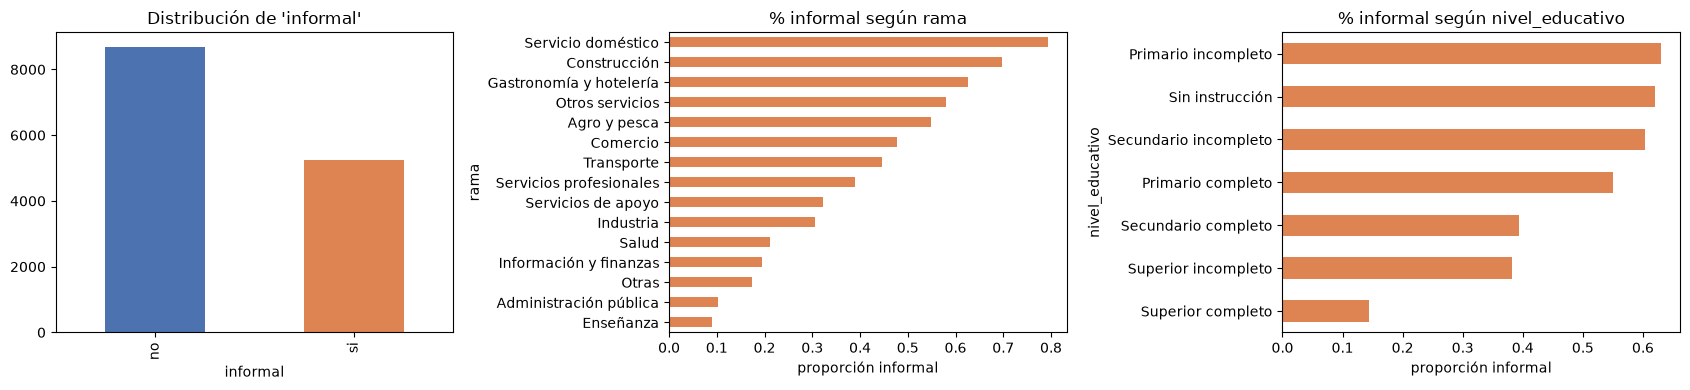

In [20]:
dist = eph["informal"].value_counts().to_frame("n")
dist["pct"] = (dist.n / dist.n.sum() * 100).round(2)
display(dist)
print(f"Ratio mayoritaria/minoritaria: {dist.n.max() / dist.n.min():.2f} : 1")
print(f"Accuracy de un clasificador trivial que siempre dice 'no': {dist.pct.max():.1f} %")

fig, axes = plt.subplots(1, 3, figsize=(17, 4))
dist.n.plot.bar(ax=axes[0], color=["#4C72B0", "#DD8452"]); axes[0].set_title("Distribución de 'informal'")
for ax, col in zip(axes[1:], ["rama", "nivel_educativo"]):
    (pd.crosstab(eph[col], eph["informal"], normalize="index")["si"].sort_values()
       .plot.barh(ax=ax, color="#DD8452"))
    ax.set_title(f"% informal según {col}"); ax.set_xlabel("proporción informal")
plt.tight_layout(); plt.show()

**Respuesta 3.b.** ≈ 62 % *no* / 38 % *si*. Es un **desbalance moderado** (≈ 1,7 : 1): no es extremo, pero
implica que la accuracy por sí sola es engañosa (el clasificador trivial ya obtiene ~62 %). Por eso se reportan
también *precision*, *recall* y *F1* de la clase **informal = si** (clase positiva), *balanced accuracy* y AUC,
y se usa partición **estratificada**.

### Preprocesamiento

- **Ordinales** → códigos enteros respetando el orden: `nivel_educativo` (0 = Sin instrucción … 6 = Superior completo),
  `antiguedad` (0 = Menos de 1 mes … 5 = Más de 5 años). `tamanio_establecimiento` ya viene en tramos ordenados.
- **Nominales** (`region`, `sexo`, `sector`, `rama`, `calificacion`, `lugar_trabajo`, `empleo_temporario`) → *one-hot*,
  con una columna adicional `_nan` cuando hay faltantes: el faltante es **estructural** (preguntas que no se le
  hacen al servicio doméstico), así que "no respondió" es en sí misma información.
- **Numéricos con faltantes** (`tamanio_establecimiento`, `antiguedad`, `horas_semanales`, `ingreso_mensual`):
  se dejan como `NaN`. Desde la versión 1.3, `DecisionTreeClassifier` maneja faltantes de forma nativa: en cada
  corte prueba enviar los `NaN` a la izquierda y a la derecha y elige lo que más reduce la impureza.
- Todas las transformaciones son mapeos fijos (no se estima nada de los datos), por lo que no hay fuga de información
  entre train y test.

In [21]:
ORD_EDU = ["Sin instrucción", "Primario incompleto", "Primario completo", "Secundario incompleto",
           "Secundario completo", "Superior incompleto", "Superior completo"]
ORD_ANT = ["Menos de 1 mes", "1 a 3 meses", "3 a 6 meses", "6 a 12 meses", "1 a 5 años", "Más de 5 años"]
NOMINALES = ["region", "sexo", "sector", "rama", "calificacion", "lugar_trabajo", "empleo_temporario"]

def preparar_eph(df):
    X = df.drop(columns="informal").copy()
    X["nivel_educativo"] = X["nivel_educativo"].map({v: i for i, v in enumerate(ORD_EDU)})
    X["antiguedad"] = X["antiguedad"].map({v: i for i, v in enumerate(ORD_ANT)})
    nominales_con_nan = [c for c in NOMINALES if X[c].isna().any()]
    X = pd.concat([
        X.drop(columns=NOMINALES),
        pd.get_dummies(X[[c for c in NOMINALES if c not in nominales_con_nan]], dtype=int),
        pd.get_dummies(X[nominales_con_nan], dummy_na=True, dtype=int),
    ], axis=1)
    return X

Xe = preparar_eph(eph)
ye = (eph["informal"] == "si").astype(int)
assert Xe["nivel_educativo"].notna().all()
print(Xe.shape)
print("Columnas con NaN (las maneja el árbol):", Xe.columns[Xe.isna().any()].tolist())
Xe.head()

(13938, 50)
Columnas con NaN (las maneja el árbol): ['tamanio_establecimiento', 'antiguedad', 'horas_semanales', 'ingreso_mensual']


,edad,nivel_educativo,tamanio_establecimiento,antiguedad,horas_semanales,ingreso_mensual,region_Cuyo,region_GBA,region_Noreste,region_Noroeste,region_Pampeana,region_Patagonia,sexo_Mujer,sexo_Varón,sector_Estatal,...,calificacion_Técnica,calificacion_nan,lugar_trabajo_Calle/ambulante,lugar_trabajo_Chacra/finca,lugar_trabajo_Domicilio de clientes,lugar_trabajo_Domicilio del patrón,lugar_trabajo_Local/oficina/taller,lugar_trabajo_Obra en construcción,lugar_trabajo_Otro,lugar_trabajo_Vehículo,lugar_trabajo_Vivienda propia,lugar_trabajo_nan,empleo_temporario_no,empleo_temporario_si,empleo_temporario_nan
0,44,6,8.0,5.0,30.0,NaN,0,0,0,0,0,1,1,0,1,...,0,0,0,0,0,0,1,0,0,0,0,0,1,0,0
1,56,5,8.0,5.0,20.0,600000.0,0,0,0,1,0,0,1,0,1,...,1,0,0,0,0,0,1,0,0,0,0,0,1,0,0
2,48,2,NaN,NaN,12.0,150000.0,0,0,0,1,0,0,1,0,0,...,0,0,0,0,0,0,0,0,0,0,0,1,0,0,1
3,26,4,3.0,4.0,40.0,1200000.0,0,0,0,1,0,0,1,0,0,...,0,0,0,0,0,0,1,0,0,0,0,0,1,0,0
4,25,4,3.0,4.0,40.0,600000.0,0,0,0,1,0,0,1,0,0,...,0,0,0,0,0,0,1,0,0,0,0,0,0,1,0


### 3.c Árbol con criterio entropía — hold-out 80/20

Train: (11150, 50) (0.376 informales) | Test: (2788, 50) (0.376 informales)


,modelo,prof.,hojas,acc_train,acc_test,bal_acc,precision,recall,f1,auc
0,"entropy, por defecto",40,1528,1.0,0.813,0.8,0.754,0.746,0.75,0.8


               precision    recall  f1-score   support

  formal (no)       0.85      0.85      0.85      1739
informal (si)       0.75      0.75      0.75      1049

     accuracy                           0.81      2788
    macro avg       0.80      0.80      0.80      2788
 weighted avg       0.81      0.81      0.81      2788



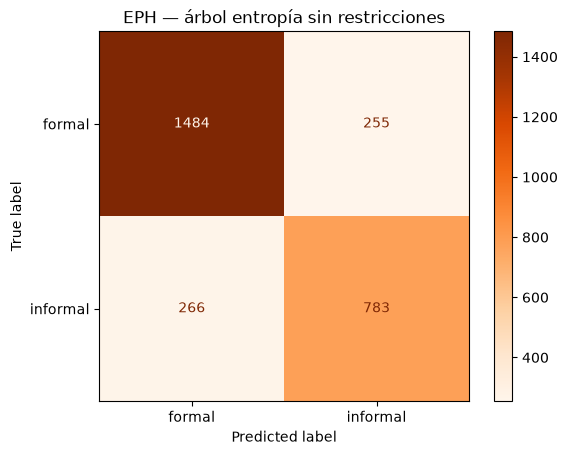

In [22]:
Xe_tr, Xe_te, ye_tr, ye_te = train_test_split(Xe, ye, test_size=0.2, stratify=ye, random_state=SEED)
print(f"Train: {Xe_tr.shape} ({ye_tr.mean():.3f} informales) | Test: {Xe_te.shape} ({ye_te.mean():.3f} informales)")

arbol_e = DecisionTreeClassifier(criterion="entropy", random_state=SEED).fit(Xe_tr, ye_tr)
display(pd.DataFrame([evaluar(arbol_e, Xe_tr, ye_tr, Xe_te, ye_te, "entropy, por defecto")]).round(3))
print(classification_report(ye_te, arbol_e.predict(Xe_te), target_names=["formal (no)", "informal (si)"]))
ConfusionMatrixDisplay.from_estimator(arbol_e, Xe_te, ye_te, display_labels=["formal", "informal"], cmap="Oranges")
plt.title("EPH — árbol entropía sin restricciones"); plt.show()

**Evaluación 3.c.** El árbol sin restricciones memoriza el entrenamiento (accuracy 100 %, profundidad 40 y
1.528 hojas) y en test obtiene 81,3 % de accuracy, F1 (informal) = 0,75 y AUC = 0,80. La brecha de 19 puntos entre
train y test es el síntoma típico del **sobreajuste**. Supera al clasificador trivial (62,4 %), pero el AUC bajo
indica que sus probabilidades (hojas casi siempre puras, 0 o 1) ordenan mal los casos.

### 3.d Combinaciones de hiperparámetros (hold-out)

In [23]:
CONFIGS = [
    dict(),                                                      # 1  sin restricciones
    dict(max_depth=3),                                           # 2
    dict(max_depth=6),                                           # 3
    dict(max_depth=10),                                          # 4
    dict(max_depth=15),                                          # 5
    dict(min_samples_split=50),                                  # 6
    dict(min_samples_split=300),                                 # 7
    dict(min_samples_leaf=10),                                   # 8
    dict(min_samples_leaf=50),                                   # 9
    dict(min_samples_leaf=200),                                  # 10
    dict(max_leaf_nodes=16),                                     # 11
    dict(max_leaf_nodes=64),                                     # 12
    dict(max_depth=10, min_samples_split=100, min_samples_leaf=30),               # 13
    dict(max_depth=12, min_samples_leaf=20, max_leaf_nodes=100),                  # 14
    dict(max_depth=8, min_samples_split=60, min_samples_leaf=25, max_leaf_nodes=50),  # 15
]
PARAMS = ["max_depth", "min_samples_split", "min_samples_leaf", "max_leaf_nodes"]
DEFAULTS = {"max_depth": None, "min_samples_split": 2, "min_samples_leaf": 1, "max_leaf_nodes": None}

def fila_config(i, cfg):
    full = {**DEFAULTS, **cfg}
    return {"#": i, **{p: ("None" if full[p] is None else full[p]) for p in PARAMS}}

filas = []
for i, cfg in enumerate(CONFIGS, 1):
    m = DecisionTreeClassifier(criterion="entropy", random_state=SEED, **cfg).fit(Xe_tr, ye_tr)
    r = evaluar(m, Xe_tr, ye_tr, Xe_te, ye_te)
    r.pop("modelo")
    filas.append({**fila_config(i, cfg), **r, "brecha": r["acc_train"] - r["acc_test"]})
tabla_holdout = pd.DataFrame(filas).set_index("#").round(3)
tabla_holdout

,max_depth,min_samples_split,min_samples_leaf,max_leaf_nodes,prof.,hojas,acc_train,acc_test,bal_acc,precision,recall,f1,auc,brecha
#,,,,,,,,,,,,,,
1,None,2,1,None,40,1528,1.000,0.813,0.800,0.754,0.746,0.750,0.800,0.187
2,3,2,1,None,3,8,0.832,0.828,0.815,0.776,0.763,0.769,0.875,0.004
3,6,2,1,None,6,55,0.852,0.844,0.823,0.829,0.738,0.781,0.909,0.008
4,10,2,1,None,10,358,0.899,0.845,0.833,0.802,0.783,0.792,0.891,0.053
5,15,2,1,None,15,963,0.954,0.829,0.813,0.785,0.750,0.767,0.841,0.126
6,None,50,1,None,27,361,0.891,0.832,0.817,0.787,0.759,0.772,0.901,0.059
7,None,300,1,None,14,80,0.854,0.844,0.826,0.820,0.751,0.784,0.913,0.010
8,None,2,10,None,21,523,0.892,0.837,0.823,0.792,0.768,0.780,0.896,0.055
9,None,2,50,None,14,138,0.860,0.842,0.831,0.791,0.787,0.789,0.914,0.018


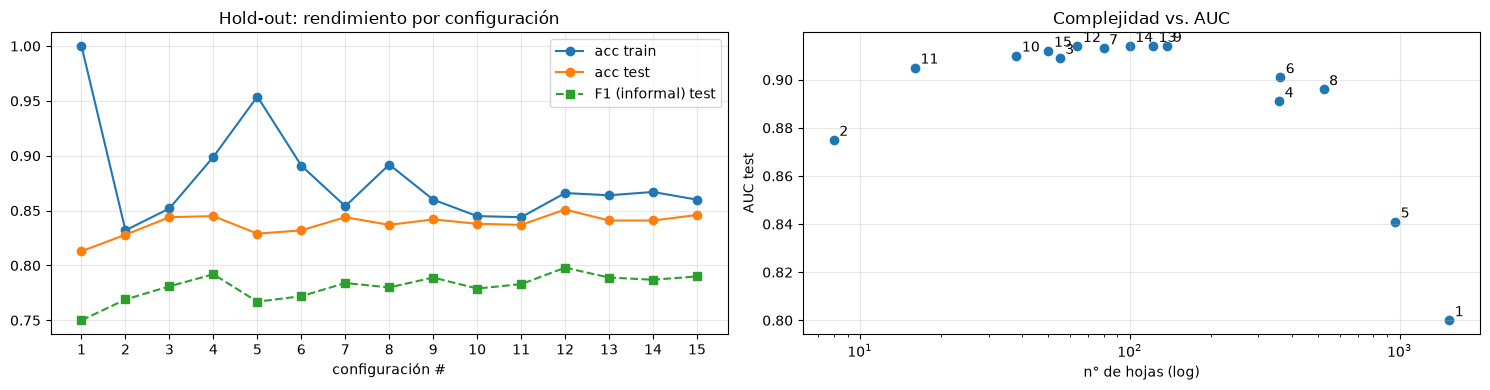

In [24]:
fig, axes = plt.subplots(1, 2, figsize=(15, 4))
t = tabla_holdout
axes[0].plot(t.index, t.acc_train, "o-", label="acc train")
axes[0].plot(t.index, t.acc_test, "o-", label="acc test")
axes[0].plot(t.index, t.f1, "s--", label="F1 (informal) test")
axes[0].set_xticks(t.index); axes[0].set_xlabel("configuración #"); axes[0].legend(); axes[0].grid(alpha=.3)
axes[0].set_title("Hold-out: rendimiento por configuración")
axes[1].scatter(t.hojas, t.auc)
for i, row in t.iterrows():
    axes[1].annotate(str(i), (row.hojas, row.auc), textcoords="offset points", xytext=(4, 3))
axes[1].set_xscale("log"); axes[1].set_xlabel("n° de hojas (log)"); axes[1].set_ylabel("AUC test")
axes[1].set_title("Complejidad vs. AUC"); axes[1].grid(alpha=.3)
plt.tight_layout(); plt.show()

### 3.e Mismas configuraciones con validación cruzada de 5 folds

La validación cruzada se aplica sobre el **80 % de entrenamiento** (5 folds estratificados): cada configuración
se entrena 5 veces con 4/5 y se valida con el 1/5 restante. Se reportan media ± desvío. El 20 % de test queda
reservado para evaluar una única vez la configuración elegida.

In [25]:
SCORING = {"acc": "accuracy", "bal_acc": "balanced_accuracy", "precision": "precision",
           "recall": "recall", "f1": "f1", "auc": "roc_auc"}
filas = []
for i, cfg in enumerate(CONFIGS, 1):
    r = cross_validate(DecisionTreeClassifier(criterion="entropy", random_state=SEED, **cfg),
                       Xe_tr, ye_tr, cv=cv5, scoring=SCORING, return_train_score=True)
    fila = fila_config(i, cfg)
    fila["acc_train_cv"] = r["train_acc"].mean()
    for k in SCORING:
        fila[f"{k}_cv"] = r[f"test_{k}"].mean()
    fila["auc_std"] = r["test_auc"].std()
    fila["f1_std"] = r["test_f1"].std()
    filas.append(fila)
tabla_cv = pd.DataFrame(filas).set_index("#").round(3)
tabla_cv

,max_depth,min_samples_split,min_samples_leaf,max_leaf_nodes,acc_train_cv,acc_cv,bal_acc_cv,precision_cv,recall_cv,f1_cv,auc_cv,auc_std,f1_std
#,,,,,,,,,,,,,
1,None,2,1,None,1.000,0.814,0.802,0.753,0.754,0.753,0.802,0.007,0.008
2,3,2,1,None,0.832,0.833,0.819,0.787,0.762,0.774,0.875,0.007,0.008
3,6,2,1,None,0.854,0.844,0.828,0.810,0.765,0.786,0.910,0.006,0.012
4,10,2,1,None,0.898,0.844,0.832,0.799,0.783,0.791,0.889,0.006,0.016
5,15,2,1,None,0.958,0.825,0.812,0.773,0.759,0.766,0.832,0.004,0.008
6,None,50,1,None,0.888,0.847,0.834,0.805,0.783,0.794,0.899,0.004,0.010
7,None,300,1,None,0.852,0.841,0.827,0.801,0.770,0.785,0.913,0.008,0.011
8,None,2,10,None,0.892,0.840,0.825,0.801,0.765,0.783,0.899,0.006,0.006
9,None,2,50,None,0.861,0.849,0.837,0.807,0.788,0.798,0.916,0.006,0.005


In [26]:
comp = pd.DataFrame({
    "acc_test (hold-out)": tabla_holdout.acc_test, "acc_cv": tabla_cv.acc_cv,
    "f1_test (hold-out)": tabla_holdout.f1, "f1_cv": tabla_cv.f1_cv,
    "auc_test (hold-out)": tabla_holdout.auc, "auc_cv": tabla_cv.auc_cv, "auc_std_cv": tabla_cv.auc_std,
})
display(comp.round(3))
mejor_cfg_idx = int(tabla_cv.auc_cv.idxmax())
print(f"Mejor configuración por AUC en CV: #{mejor_cfg_idx} -> {CONFIGS[mejor_cfg_idx - 1]}")
print(f"Mejor configuración por F1 en CV:  #{int(tabla_cv.f1_cv.idxmax())} -> {CONFIGS[int(tabla_cv.f1_cv.idxmax()) - 1]}")

,acc_test (hold-out),acc_cv,f1_test (hold-out),f1_cv,auc_test (hold-out),auc_cv,auc_std_cv
#,,,,,,,
1,0.813,0.814,0.750,0.753,0.800,0.802,0.007
2,0.828,0.833,0.769,0.774,0.875,0.875,0.007
3,0.844,0.844,0.781,0.786,0.909,0.910,0.006
4,0.845,0.844,0.792,0.791,0.891,0.889,0.006
5,0.829,0.825,0.767,0.766,0.841,0.832,0.004
6,0.832,0.847,0.772,0.794,0.901,0.899,0.004
7,0.844,0.841,0.784,0.785,0.913,0.913,0.008
8,0.837,0.840,0.780,0.783,0.896,0.899,0.006
9,0.842,0.849,0.789,0.798,0.914,0.916,0.006


Mejor configuración por AUC en CV: #9 -> {'min_samples_leaf': 50}
Mejor configuración por F1 en CV:  #12 -> {'max_leaf_nodes': 64}


#### Modelo seleccionado: evaluación final en test e interpretación

,modelo,prof.,hojas,acc_train,acc_test,bal_acc,precision,recall,f1,auc
0,3.c sin restricciones,40,1528,1.00,0.813,0.800,0.754,0.746,0.750,0.800
1,#9 {'min_samples_leaf': 50},14,138,0.86,0.842,0.831,0.791,0.787,0.789,0.914


               precision    recall  f1-score   support

  formal (no)       0.87      0.87      0.87      1739
informal (si)       0.79      0.79      0.79      1049

     accuracy                           0.84      2788
    macro avg       0.83      0.83      0.83      2788
 weighted avg       0.84      0.84      0.84      2788



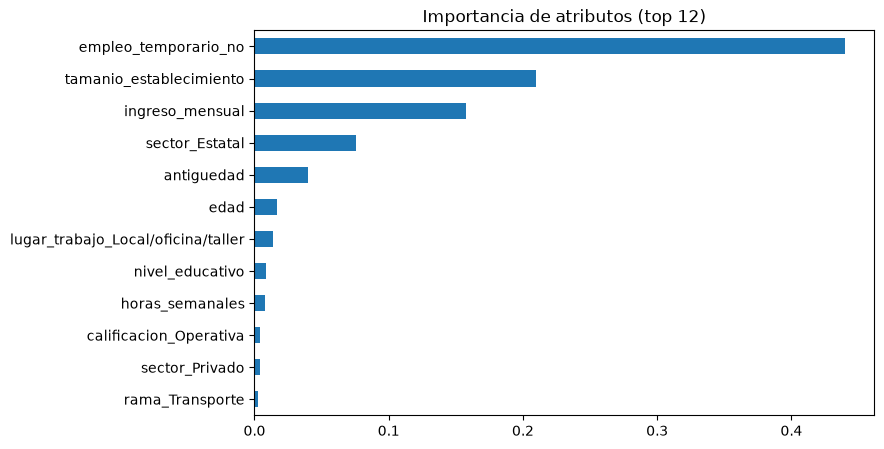

In [27]:
cfg_final = CONFIGS[mejor_cfg_idx - 1]
final_e = DecisionTreeClassifier(criterion="entropy", random_state=SEED, **cfg_final).fit(Xe_tr, ye_tr)
display(pd.DataFrame([evaluar(arbol_e, Xe_tr, ye_tr, Xe_te, ye_te, "3.c sin restricciones"),
                      evaluar(final_e, Xe_tr, ye_tr, Xe_te, ye_te, f"#{mejor_cfg_idx} {cfg_final}")]).round(3))
print(classification_report(ye_te, final_e.predict(Xe_te), target_names=["formal (no)", "informal (si)"]))

imp_e = pd.Series(final_e.feature_importances_, index=Xe.columns).sort_values(ascending=False)
imp_e.head(12).sort_values().plot.barh(figsize=(8, 5), title="Importancia de atributos (top 12)")
plt.show()

|--- empleo_temporario_no <= 0.50
|   |--- tamanio_establecimiento <= 5.50
|   |   |--- ingreso_mensual <= 690000.00
|   |   |   |--- truncated branch of depth 4
|   |   |--- ingreso_mensual >  690000.00
|   |   |   |--- truncated branch of depth 2
|   |--- tamanio_establecimiento >  5.50
|   |   |--- ingreso_mensual <= 605000.00
|   |   |   |--- truncated branch of depth 9
|   |   |--- ingreso_mensual >  605000.00
|   |   |   |--- truncated branch of depth 5
|--- empleo_temporario_no >  0.50
|   |--- tamanio_establecimiento <= 6.50
|   |   |--- ingreso_mensual <= 805000.00
|   |   |   |--- truncated branch of depth 9
|   |   |--- ingreso_mensual >  805000.00
|   |   |   |--- truncated branch of depth 7
|   |--- tamanio_establecimiento >  6.50
|   |   |--- sector_Estatal <= 0.50
|   |   |   |--- truncated branch of depth 12
|   |   |--- sector_Estatal >  0.50
|   |   |   |--- truncated branch of depth 8



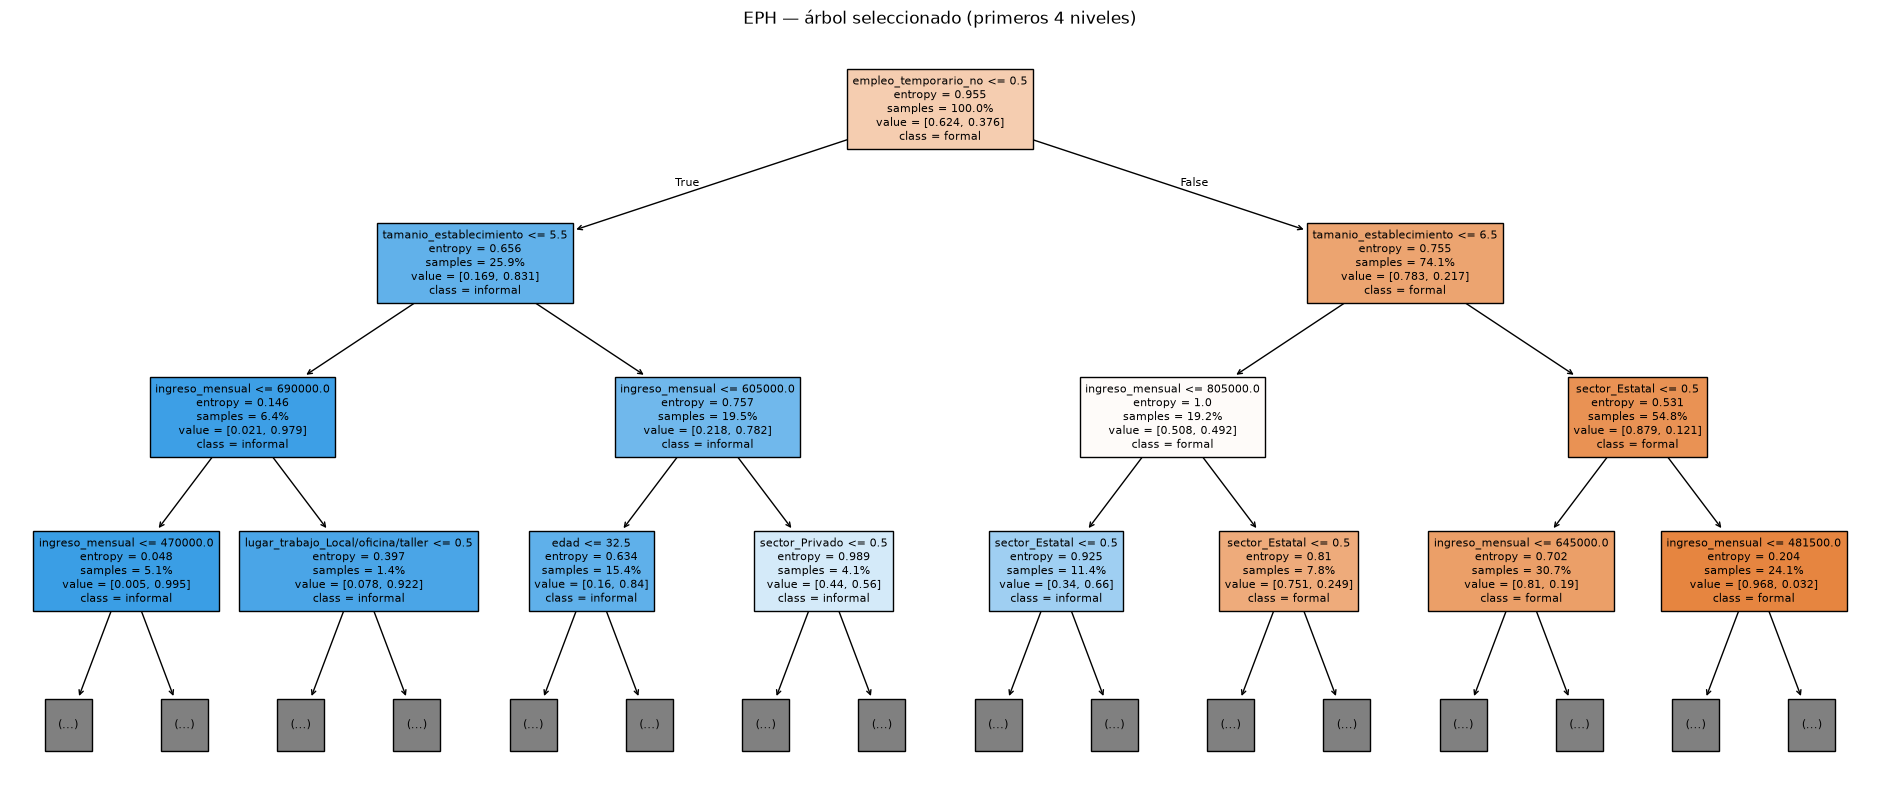

In [28]:
print(export_text(final_e, feature_names=list(Xe.columns), max_depth=2))
plt.figure(figsize=(24, 10))
plot_tree(final_e, feature_names=Xe.columns, class_names=["formal", "informal"], filled=True,
          max_depth=3, fontsize=8, proportion=True)
plt.title("EPH — árbol seleccionado (primeros 4 niveles)"); plt.show()

#### Complemento: efecto de `class_weight="balanced"`

No es uno de los parámetros pedidos, pero responde al desbalance del punto 3.b: penaliza más los errores
sobre la clase minoritaria.

In [29]:
r_bal = cross_validate(DecisionTreeClassifier(criterion="entropy", random_state=SEED, class_weight="balanced", **cfg_final),
                       Xe_tr, ye_tr, cv=cv5, scoring=SCORING)
pd.DataFrame({
    "sin pesos (CV)": tabla_cv.loc[mejor_cfg_idx, [f"{k}_cv" for k in SCORING]].values,
    "class_weight=balanced (CV)": [r_bal[f"test_{k}"].mean() for k in SCORING],
}, index=list(SCORING)).round(3)

,sin pesos (CV),class_weight=balanced (CV)
acc,0.849,0.840
bal_acc,0.837,0.842
precision,0.807,0.758
recall,0.788,0.846
f1,0.798,0.800
auc,0.916,0.915


### 3.f Conclusiones

Ver el desarrollo completo en `TP03_Explicacion_Teorica.md`. En síntesis:

1. El árbol sin restricciones sobreajusta fuertemente (100 % train vs. 81,3 % test; 1.528 hojas; AUC 0,80).
2. Los cuatro hiperparámetros de pre-poda reducen la brecha y mejoran el test: con 38–138 hojas se llega a
   accuracy ≈ 0,84–0,85 y AUC ≈ 0,91, es decir, **árboles 10–40 veces más chicos que generalizan mejor**.
   Los extremos fallan: `max_depth=3` (8 hojas) subajusta (AUC 0,875) y `max_depth=15` vuelve a sobreajustar.
3. Los mejores resultados vienen de limitar el tamaño de las hojas o su cantidad: `min_samples_leaf=50` (#9, mejor
   AUC en CV = 0,916) y `max_leaf_nodes=64` (#12, mejor F1 en CV = 0,799). Las combinaciones (#13–#15) quedan
   empatadas con ellas: superado cierto nivel de regularización, el resultado se estabiliza.
4. La validación cruzada confirma el ranking del hold-out con desvíos muy chicos (AUC ± 0,004–0,008). Las diferencias
   de 0,001–0,003 entre las mejores configuraciones están **dentro del ruido**, así que conviene elegir la más simple.
   Además, permite elegir sin usar el test: el modelo #9 en test da 84,2 % de accuracy, F1 0,789 y AUC 0,914,
   valores casi iguales a los de CV (no hay optimismo por la selección).
5. Variables más importantes: **`empleo_temporario`** (44 %; su "no" separa a los permanentes de los temporarios **y**
   del servicio doméstico, cuyo valor es faltante), **tamaño del establecimiento** (21 %), **ingreso** (16 %),
   **sector estatal** (8 %) y **antigüedad**. Esto coincide con lo que se sabe de la informalidad: es mayor en
   empleos temporarios, en establecimientos chicos, con ingresos bajos y en el sector privado.
6. Por el desbalance moderado conviene mirar F1/recall/AUC además de la accuracy. `class_weight="balanced"` sube el
   recall de los informales de 0,79 a 0,85 a cambio de precisión (0,81 → 0,76), con F1 y AUC casi iguales: es
   una decisión de negocio (¿qué cuesta más, un falso positivo o un falso negativo?).